# Student Depression Classification
## Exploratory Data Analysis (EDA)

### 1. Project Overview

This project aims to analyze student-related data and explore patterns associated with depression classification using data analysis and machine learning techniques.

The dataset contains demographic, academic, social, financial, and health-related information about students. The target variable is `Depression`, which indicates whether a student is classified as having depression (`Yes`) or not (`No`).

### 2. Objectives

The main objectives of this notebook are:

- Understand the structure and characteristics of the dataset.
- Examine numerical and categorical features.
- Assess data quality by identifying missing values, duplicates, and potential outliers.
- Explore feature distributions and statistical properties.
- Analyze the target variable distribution.
- Investigate relationships between student characteristics and the target variable.
- Identify potential data issues and patterns that may affect model performance.

### 3. Dataset Description

The dataset consists of **4,464 observations and 13 columns**.

It includes the following categories of information:

- **Demographic:** Gender, Age, Home division.
- **Academic:** Current semester, CGPA.
- **Social and Personal:** Family background, Relationship status, Marital status, Living style, Friend circle.
- **Health-related:** Health condition.
- **Financial:** Cost without study.
- **Target:** Depression.

Dataset Source: [Kaggle - Student Depression Detection Dataset](https://www.kaggle.com/datasets/mkhoirulmustaqim/student-depression-detection-dataset/data)

### 4. Notebook Structure

This notebook is organized into the following sections:

1. Data Loading and Initial Inspection
2. Descriptive Statistics
3. Data Quality Assessment
4. Outlier Detection
5. Univariate Analysis
6. Target Variable Analysis
7. Bivariate Analysis
8. Key Findings and Conclusions

### 5. Important Considerations

This dataset is used for educational and machine learning purposes. The target variable represents the dataset/'s depression classification and should not be interpreted as a clinical diagnosis.

Potential relationships between features and the target variable will be investigated carefully to identify possible data leakage or dataset construction issues.

The analysis will focus on understanding the data before making preprocessing decisions or training predictive models.

In [7]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [8]:
df = pd.read_csv("../data/raw/Student_Depression_Dataset.csv")

In [9]:
df.head()

,Gender,Age,Family_background,Relationship_status,Marital_status,Living_style,Current_semester,CGPA,friend_circle,Health_condition,Cost_without_study,Home_division,Depression
0,Female,22,Middle class,Single,Unmarried,Bachelor,8,3.43,Yes,Critical,10113,Chittagong,Yes
1,Male,19,Middle class,Single,Unmarried,Bachelor,2,3.70,Yes,Abnormal,13815,Chittagong,Yes
2,Male,23,Middle class,Single,Unmarried,Family,8,3.28,No,Abnormal,15450,Dhaka,Yes
3,Male,20,Middle class,Complicated,Unmarried,Family,2,3.77,No,Good,17413,Dhaka,No
4,Female,21,Middle class,Single,Unmarried,Family,1,4.00,No,Abnormal,16693,Dhaka,Yes


In [10]:
# Calculate the total number of missing values
df.isnull().sum().sum()

np.int64(0)

In [11]:
# Count the number of duplicated rows
df.duplicated().sum().sum()

np.int64(0)

In [12]:
# Detect potential outliers using the IQR method
for col in df.select_dtypes('number').columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\nFeature: {col}")
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))




Feature: Age
Lower Bound: 16.5
Upper Bound: 28.5
Number of Outliers: 0

Feature: Current_semester
Lower Bound: -3.0
Upper Bound: 13.0
Number of Outliers: 0

Feature: CGPA
Lower Bound: 2.3249999999999993
Upper Bound: 4.525
Number of Outliers: 12

Feature: Cost_without_study
Lower Bound: -7908.5
Upper Bound: 29447.5
Number of Outliers: 36


**Observations:**

The IQR method identified 12 potential outliers in `CGPA` and 36 in `Cost_without_study`.

However, these observations are not necessarily invalid. The CGPA values remain within the expected range of 2.25 to 4.00, and the high cost values require further contextual investigation.

Therefore, no observations are removed or modified at this stage.

In [13]:
len(df[(df["CGPA"] < 2.25) | (df["CGPA"] > 4)])

0

In [14]:
print(df['Cost_without_study'].describe())

print("\nHighest values:")
print(
    df['Cost_without_study']
    .value_counts()
    .sort_index(ascending=False)
    .head(15)
)

count     4464.000000
mean     11242.978271
std       6640.144019
min          0.000000
25%       6100.000000
50%       9500.000000
75%      15439.000000
max      32000.000000
Name: Cost_without_study, dtype: float64

Highest values:
Cost_without_study
32000     2
31707     1
30866     1
30634     1
30421     1
30301     1
30000    13
29990     1
29856     2
29796     1
29769     1
29747     1
29702     1
29658     2
29635     3
Name: count, dtype: int64


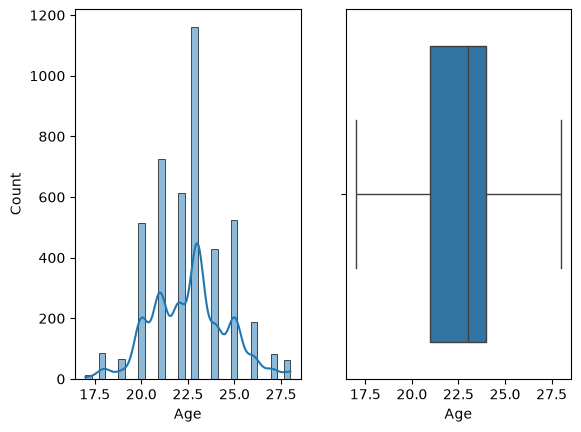

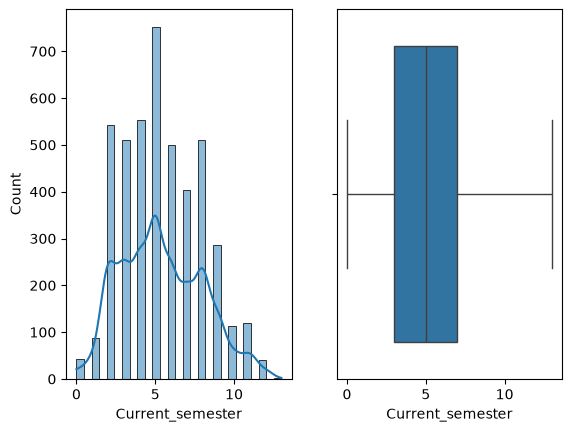

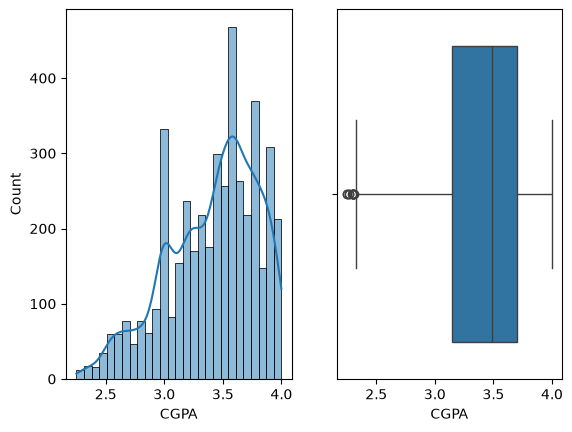

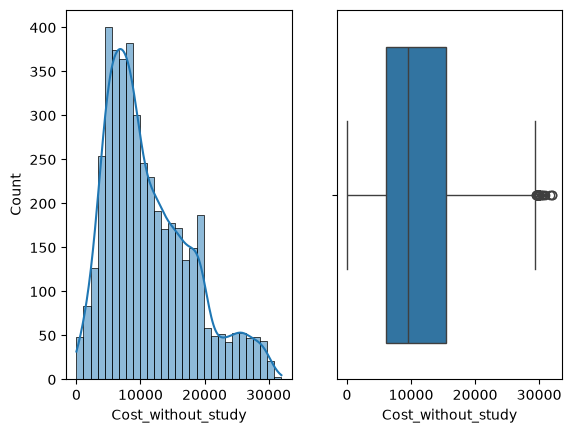

In [15]:
# Visualize numerical feature distributions using histograms and boxplots
for col in df.select_dtypes('number').columns:
    fig, ax = plt.subplots(1,2)
    sns.histplot(x=df[col],kde=True,ax=ax[0])
    sns.boxplot(x=df[col],ax=ax[1])
    plt.show()

In [16]:
# Display the frequency distribution of categorical features
for col in df.select_dtypes("str").columns:
    print(df[col].value_counts())
    print()

Gender
Female    2462
Male      2002
Name: count, dtype: int64

Family_background
Middle class          2642
Lower Middle class    1151
Rich class             671
Name: count, dtype: int64

Relationship_status
Single               2803
In a Relationship    1457
Complicated           204
Name: count, dtype: int64

Marital_status
Unmarried    3619
Married       725
Separated     120
Name: count, dtype: int64

Living_style
Bachelor    2449
Family      2015
Name: count, dtype: int64

friend_circle
Yes    3215
No     1249
Name: count, dtype: int64

Health_condition
Normal      1787
Good        1162
Abnormal     881
Critical     634
Name: count, dtype: int64

Home_division
Dhaka         1527
Khulna         548
Rajshahi       488
Sylhet         445
Chittagong     400
Rangpur        363
Barisal        355
Mymensingh     338
Name: count, dtype: int64

Depression
No     3263
Yes    1201
Name: count, dtype: int64

